<a href="https://colab.research.google.com/github/gachet/ad-1-26/blob/main/algo/Actividad3_11_Jav.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

In [ ]:
heart_data = pd.read_csv('https://drive.google.com/uc?id=1VNg7M4u4wluLLqEeSgU3EEduFd6Q84NZ')
display(heart_data.head())

,Size,Bedrooms,Price
0,2104,3,399900
1,1600,3,329900
2,2400,3,369000
3,1416,2,232000
4,3000,4,539900


Preparacion de datos


In [ ]:
X = heart_data[['Size', 'Bedrooms']]
Y = heart_data['Price']
X_scaled = (X - X.mean()) / X.std()

Gradiente descendiente

In [ ]:
X_scaled = np.c_[np.ones(X_scaled.shape[0]), X_scaled]
theta = np.zeros(X_scaled.shape[1])
alpha = 0.01
epsilon = 1e-5

cost_history = []
previous_cost = float('inf')
i = 0

while True:
    predictions = X_scaled.dot(theta)
    errors = predictions - heart_data['Price']
    gradient = X_scaled.T.dot(errors) / len(heart_data)
    theta = theta - alpha * gradient
    cost = np.mean(errors**2) / 2
    cost_history.append(cost)

    if abs(previous_cost - cost) < epsilon:
        print(f"Converged at iteration {i}")
        break
    previous_cost = cost
    i += 1


print("Coefficients (theta):", theta)

Converged at iteration 3223
Coefficients (theta): [340412.65957447 110630.99718115  -6649.42117312]


Función de pérdida



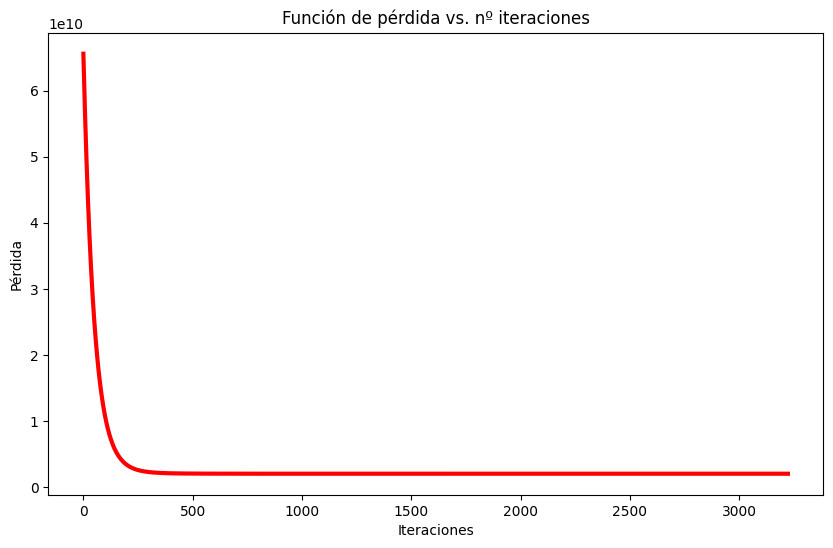

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(range(len(cost_history)), cost_history, color='red', linewidth=3)
plt.xlabel("Iteraciones")
plt.ylabel("Pérdida")
plt.title("Función de pérdida vs. nº iteraciones")
plt.show()

Comprobamos la solución con skitlearn


In [ ]:
betaHat = np.linalg.inv(X_scaled.T.dot(X_scaled)).dot(X_scaled.T).dot(Y)
print("Coeficientes:")
print(betaHat)

Coeficientes:
[340412.65957447 110631.05027885  -6649.47427082]
